In [154]:
import pandas as pd
A=pd.read_csv('healthcare/calories.csv')
B=pd.read_csv('healthcare/exercise.csv')
data=pd.concat([A,B],axis=1)
# join='inner': only keeps the rows with smae column 
# join='outer': keeps both rows and fill the missing value as nan
print(data.shape)
data.tail()


(15000, 10)


,User_ID,Calories,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
14995,15644082,45.0,15644082,female,20,193.0,86.0,11.0,92.0,40.4
14996,17212577,23.0,17212577,female,27,165.0,65.0,6.0,85.0,39.2
14997,17271188,75.0,17271188,female,43,159.0,58.0,16.0,90.0,40.1
14998,18643037,11.0,18643037,male,78,193.0,97.0,2.0,84.0,38.3
14999,11751526,98.0,11751526,male,63,173.0,79.0,18.0,92.0,40.5


In [155]:
data=data.drop('User_ID',axis=1)
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Calories    15000 non-null  float64
 1   Gender      15000 non-null  str    
 2   Age         15000 non-null  int64  
 3   Height      15000 non-null  float64
 4   Weight      15000 non-null  float64
 5   Duration    15000 non-null  float64
 6   Heart_Rate  15000 non-null  float64
 7   Body_Temp   15000 non-null  float64
dtypes: float64(6), int64(1), str(1)
memory usage: 937.6 KB


In [156]:
data.describe()

,Calories,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,89.539533,42.789800,174.465133,74.966867,15.530600,95.518533,40.025453
std,62.456978,16.980264,14.258114,15.035657,8.319203,9.583328,0.779230
min,1.000000,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000
25%,35.000000,28.000000,164.000000,63.000000,8.000000,88.000000,39.600000
50%,79.000000,39.000000,175.000000,74.000000,16.000000,96.000000,40.200000
75%,138.000000,56.000000,185.000000,87.000000,23.000000,103.000000,40.600000
max,314.000000,79.000000,222.000000,132.000000,30.000000,128.000000,41.500000


In [157]:
# numerical correlation
num_data=data.drop('Gender',axis=1)
corr_matrix=num_data.corr()
print(corr_matrix)

            Calories       Age    Height    Weight  Duration  Heart_Rate  \
Calories    1.000000  0.154395  0.017537  0.035481  0.955421    0.897882   
Age         0.154395  1.000000  0.009554  0.090094  0.013247    0.010482   
Height      0.017537  0.009554  1.000000  0.958451 -0.004625    0.000528   
Weight      0.035481  0.090094  0.958451  1.000000 -0.001884    0.004311   
Duration    0.955421  0.013247 -0.004625 -0.001884  1.000000    0.852869   
Heart_Rate  0.897882  0.010482  0.000528  0.004311  0.852869    1.000000   
Body_Temp   0.824558  0.013175  0.001200  0.004095  0.903167    0.771529   

            Body_Temp  
Calories     0.824558  
Age          0.013175  
Height       0.001200  
Weight       0.004095  
Duration     0.903167  
Heart_Rate   0.771529  
Body_Temp    1.000000  


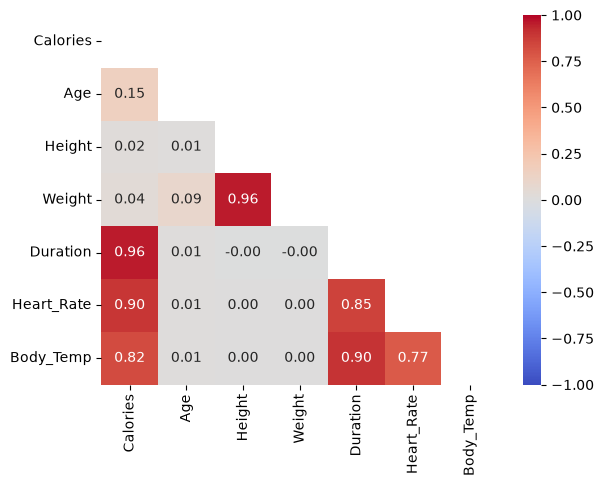

In [158]:
import numpy as np
mask=np.triu(np.ones_like(corr_matrix,dtype=bool))
import seaborn as sns
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
) 
corr_feature=['Duration']
# the rest are multicollinearity with less correlation value 

In [159]:
gender=data['Gender'].astype('category')
mapping={val: i for i,val in enumerate (gender.cat.categories)}
gender=gender.cat.codes
print(mapping)
data['Gender']=gender
import scipy.stats as stats
r_pb,p_pb=stats.pointbiserialr(gender,data['Calories'])
print(p_pb,r_pb)
if p_pb<0.05:
    print("correlated")
    if abs(r_pb)>0.5:
        print("strong relationship")
    else:
        print("weak relationship")
else:
    print("no relationship")

{'female': 0, 'male': 1}
0.006175846213736116 0.022357162090988793
correlated
weak relationship


In [160]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Calories    15000 non-null  float64
 1   Gender      15000 non-null  int8   
 2   Age         15000 non-null  int64  
 3   Height      15000 non-null  float64
 4   Weight      15000 non-null  float64
 5   Duration    15000 non-null  float64
 6   Heart_Rate  15000 non-null  float64
 7   Body_Temp   15000 non-null  float64
dtypes: float64(6), int64(1), int8(1)
memory usage: 835.1 KB


In [161]:
data.tail()

,Calories,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
14995,45.0,0,20,193.0,86.0,11.0,92.0,40.4
14996,23.0,0,27,165.0,65.0,6.0,85.0,39.2
14997,75.0,0,43,159.0,58.0,16.0,90.0,40.1
14998,11.0,1,78,193.0,97.0,2.0,84.0,38.3
14999,98.0,1,63,173.0,79.0,18.0,92.0,40.5


In [162]:
def correlation_ratio(categories,values):
    categories=np.asarray(categories)
    values=np.asarray(values,dtype=float)
    grand_mean=values.mean()
    ss_between=sum(
        (categories==c).sum()*(values[categories==c].mean()-grand_mean)**2
        for c in np.unique(categories)
    )
    ss_total=((values-grand_mean)**2).sum()
    return np.sqrt(ss_between/ss_total)

eta=correlation_ratio(data['Gender'],data['Calories'])

if eta>0.14:
    print("strong relationship")
else:
    print("weak relationship")

weak relationship


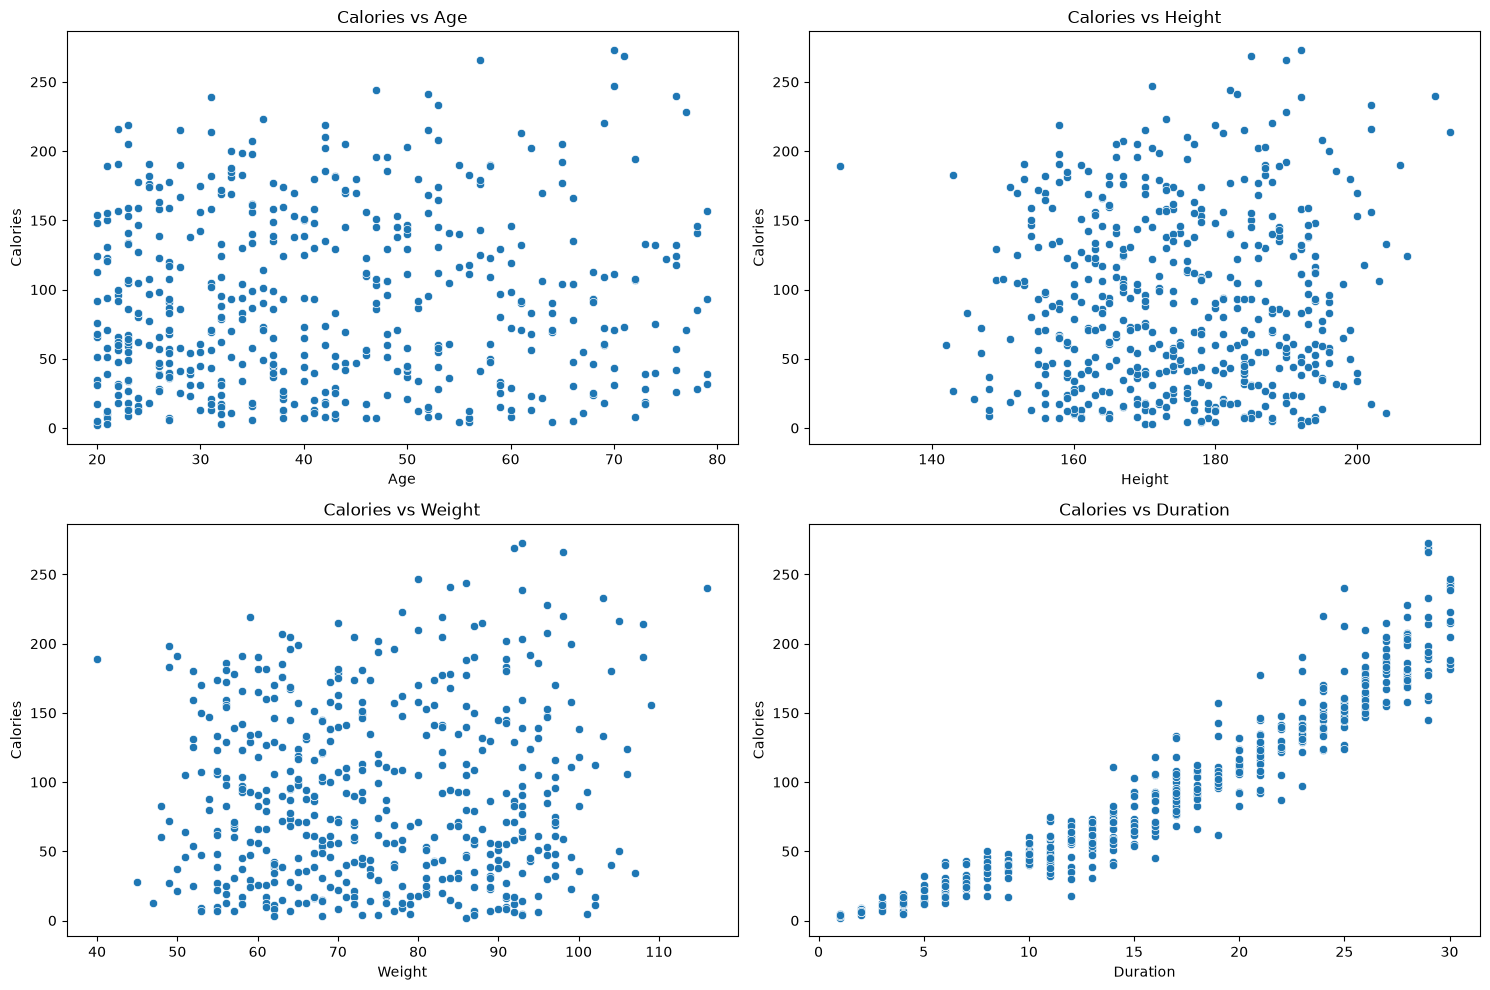

In [163]:
features=['Age','Height','Weight','Duration']
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,2,figsize=(15,10))
axes_flat=axes.flatten()
x=data.sample(500)
for i,col in enumerate(features):
# store the smaller subset into x
    sns.scatterplot(x=col,y='Calories',data=x,ax=axes_flat[i])
# data=x only takes random sample of 500 rows from main dataset 
    axes_flat[i].set_title(f"Calories vs {col}")
plt.tight_layout()

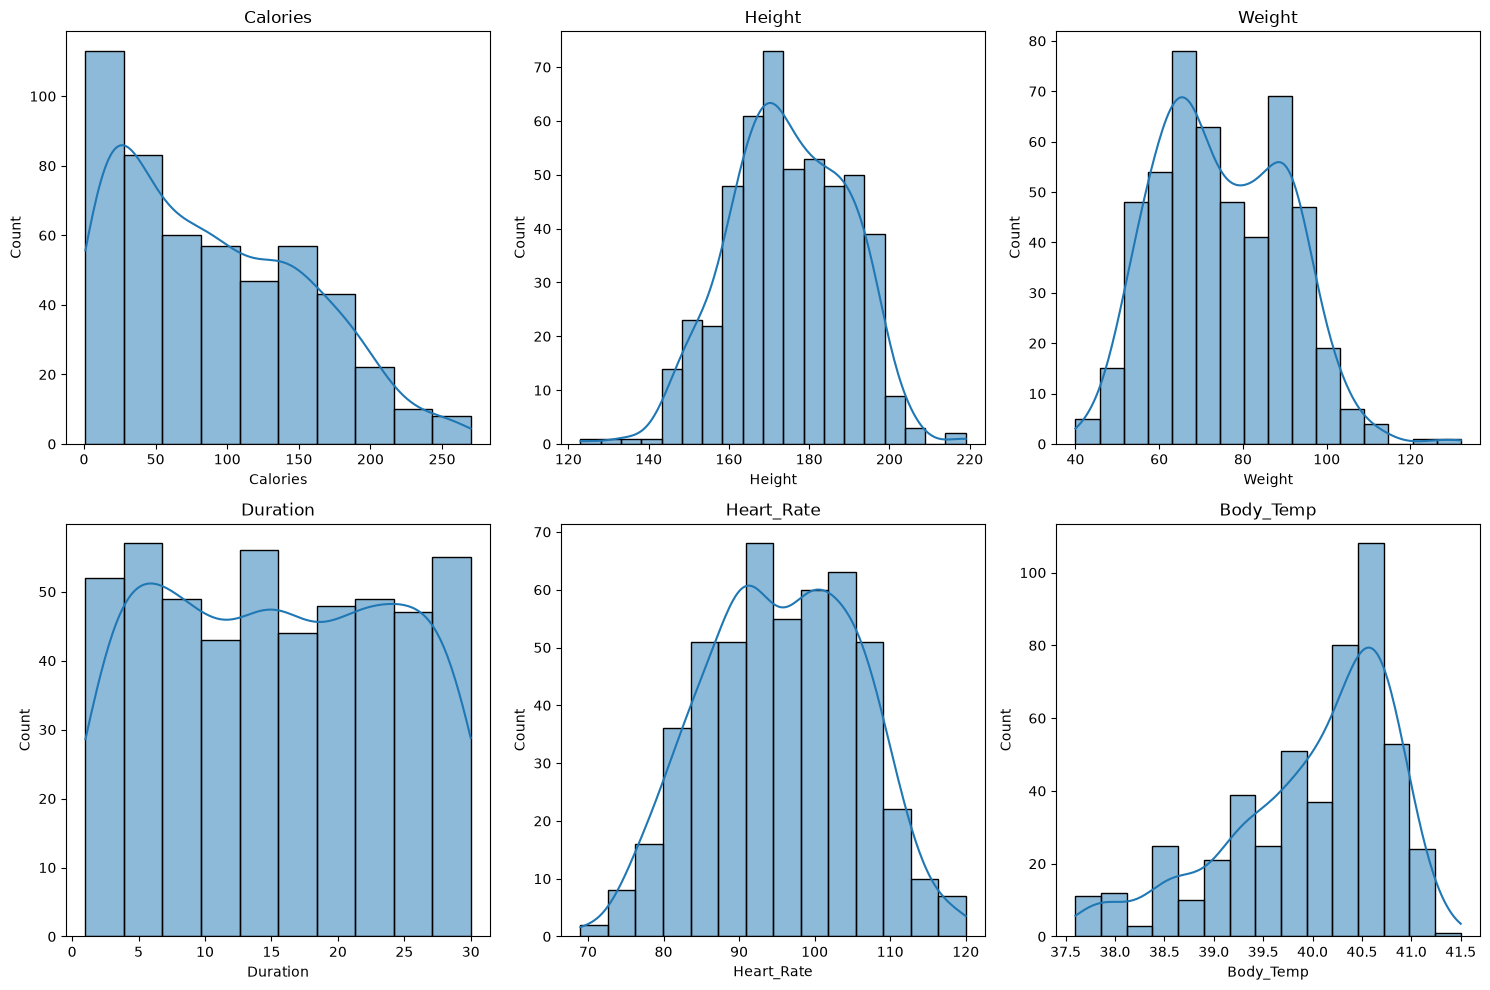

In [164]:
features=data.select_dtypes(include='float').columns
fig,axes=plt.subplots(2,3,figsize=(15,10))
axes_flat=axes.flatten()
x=data.sample(500)
for i,col in enumerate(features):
    sns.histplot(data=x,x=col,ax=axes_flat[i],kde=True)
    axes_flat[i].set_title(f"{col}")
plt.tight_layout()

In [165]:
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

features=data.drop('Calories',axis=1)
target=data['Calories']
X_train,X_test,y_train,y_test=train_test_split(features,target,test_size=0.3,random_state=22)

scaler=StandardScaler()
models={
    'Lasso':Lasso(),
    # feature selection regularized linear regression model
    'Ridge':Ridge(),
    # regularized linear regression 
    'LinearReg':LinearRegression(),
    'xgboost':XGBRegressor(),
    'randomForest':RandomForestRegressor()
}
pred_error={}

from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline
for mname,model in models.items():
    pipe=make_pipeline(StandardScaler(),model)
    pipe.fit(X_train,y_train)
    y_pred=pipe.predict(X_test)
    print(f"{mname}prediction error:{mean_absolute_error(y_test,y_pred)}")
    pred_error[mname]=mean_absolute_error(y_test,y_pred)
best_model=min(pred_error, key=pred_error.get)
print(f"Best model is: {best_model} with MAE of {pred_error[best_model]}")



Lassoprediction error:9.039832697161703
Ridgeprediction error:8.323167859131829
LinearRegprediction error:8.323311110163118
xgboostprediction error:1.5456512565612792
randomForestprediction error:1.845786666666667
Best model is: xgboost with MAE of 1.5456512565612792


In [167]:
# find the best hyperparameter
from sklearn.model_selection import GridSearchCV
model=XGBRegressor()

param_grid={
    'n_estimators':[50,100],
    'max_depth':[3,5],
    'learning_rate':[0.01,0.1],
# n_estimator: number of tree to build, tradeoff between model performance and computation time
# learning rate: tradeoff between overfitting and more trees 
}
from sklearn.model_selection import cross_val_predict
grid_search=GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error'
    # scoring: accuracy, precision, f1, neg_mean_squared_error
    # higher scores are better
)
grid_search.fit(X_train,y_train)
print(f"Best Hyperparameters found:{grid_search.best_params_}")
best_tunned_model=grid_search.best_estimator_

tunned_preds=best_tunned_model.predict(X_test)
print(f" Tuned Test MAE: {mean_absolute_error(y_test,tunned_preds)}")


Best Hyperparameters found:{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}
 Tuned Test MAE: 1.5442975294225745
